Training data shape: (27455, 28, 28)
Testing data shape: (7172, 28, 28)
Training labels: 0 to 23
Epoch 1/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.1865 - loss: 2.7218 - val_accuracy: 0.4738 - val_loss: 1.5719
Epoch 2/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5521 - loss: 1.4141 - val_accuracy: 0.6890 - val_loss: 0.9781
Epoch 3/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6921 - loss: 0.9756 - val_accuracy: 0.7353 - val_loss: 0.7694
Epoch 4/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7657 - loss: 0.7329 - val_accuracy: 0.8088 - val_loss: 0.5932
Epoch 5/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8258 - loss: 0.5537 - val_accuracy: 0.8394 - val_loss: 0.4635
Epoch 6/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8562 - loss: 0.4413 - val_accuracy: 0.9250 - val_loss: 0.2781
Epoch 7/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9039 - loss: 0.3185 - val_accuracy: 0.9286 - val_loss: 0.2469
Epoch 8

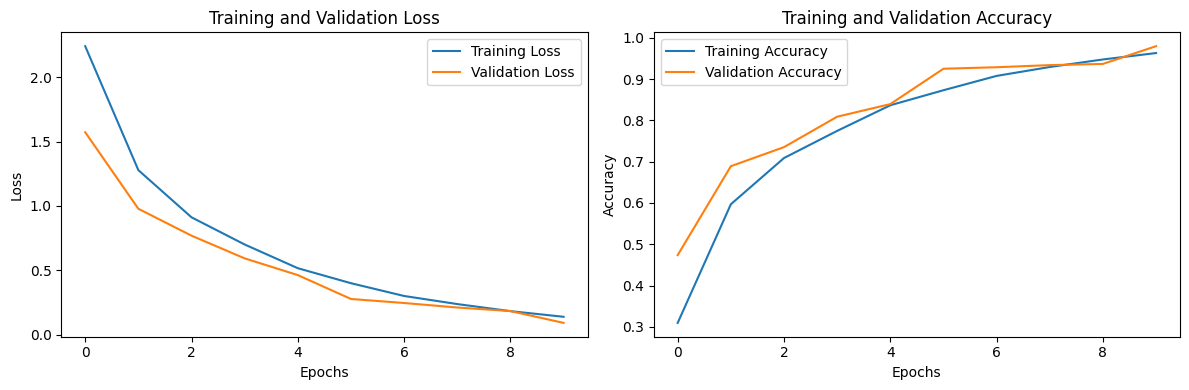

In [ ]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

train_data = pd.read_csv("Datasets/FNN_CNN/S_MNIST/sign_mnist_train.csv")
test_data = pd.read_csv("Datasets/FNN_CNN/S_MNIST/sign_mnist_test.csv")

x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

y_train[y_train > 9] -= 1
y_test[y_test > 9] -= 1

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 28, 28)
x_test = x_test.reshape(-1, 28, 28)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Training labels:", y_train.min(), "to", y_train.max())

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(24, activation='softmax')
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()